### Add complete ORF1B p-distance values to the table with PCR-fragment p-distance values

In [30]:
import pandas as pd

pcr = pd.read_csv("pairs_nt_pdist_gt02_pcr_genbank_headers.csv")
comp = pd.read_csv("pairs_complete_orf1b_genbank_headers.csv")

pcr = pcr.rename(columns={"value.x": "nt p-distance pcr", "value.y": "aa p-distance pcr"})
comp = comp.rename(columns={"value.x": "nt p-distance complete", "value.y": "aa p-distance complete"})

merged = pcr.merge(comp, on=["row", "col"], how="left")

merged.to_csv("pairs_nt_pdist_gt02_pcr_and_complete_genbank_headers.csv", index=False)


print(merged.head())
print("rows:", len(merged), "| missing complete:", merged["nt p-distance complete"].isna().sum())

                                                 row  \
0                 LC047793/JPN/NA/Bos-taurus/2009/NA   
1  MZ819168/CHL/PoAstV5-Swine-CHI-FB016-2017/Sus-...   
2      OP963600/CHN/NA/Hipposideros-larvatus/2015/NA   
3  PQ678017/CHN/LJNL-YNSC78/Crocidura-fuliginosa/...   
4  MZ819170/CHL/PoAstV5-Swine-CHI-FB036-2017/Sus-...   

                                                 col  nt p-distance pcr  \
0  PQ678017/CHN/LJNL-YNSC78/Crocidura-fuliginosa/...           0.535014   
1      OP963600/CHN/NA/Hipposideros-larvatus/2015/NA           0.535014   
2  MZ819168/CHL/PoAstV5-Swine-CHI-FB016-2017/Sus-...           0.535014   
3                 LC047793/JPN/NA/Bos-taurus/2009/NA           0.535014   
4      OP963600/CHN/NA/Hipposideros-larvatus/2015/NA           0.532213   

   aa p-distance pcr  nt p-distance complete  aa p-distance complete  
0           0.512605                0.506667                0.545263  
1           0.504202                0.483062                0.526423  

### Check species relations (same or different)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("pairs_nt_pdist_gt02_pcr_and_complete_genbank_headers.csv", sep=",")

def get_species(name):
    if pd.isna(name):
        return None
    parts = str(name).split("/")
    sp = parts[-1].strip()
    #print(sp)
    if sp == "" or sp == "NA" or sp.lower() == "nan":
        return None
    return sp

df["species_row"] = df["row"].apply(get_species)
df["species_col"] = df["col"].apply(get_species)

def species_relation(r, c):
    if r is None or c is None:
        return "unknown"
    return "same" if r == c else "different"

df["species_relation"] = [
    species_relation(r, c) for r, c in zip(df["species_row"], df["species_col"])
]

df[["row", "species_row", "col", "species_col", "species_relation"]]

,row,species_row,col,species_col,species_relation
0,LC047793/JPN/NA/Bos-taurus/2009/NA,NaN,PQ678017/CHN/LJNL-YNSC78/Crocidura-fuliginosa/...,NaN,different
1,MZ819168/CHL/PoAstV5-Swine-CHI-FB016-2017/Sus-...,NaN,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,NaN,different
2,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,NaN,MZ819168/CHL/PoAstV5-Swine-CHI-FB016-2017/Sus-...,NaN,different
3,PQ678017/CHN/LJNL-YNSC78/Crocidura-fuliginosa/...,NaN,LC047793/JPN/NA/Bos-taurus/2009/NA,NaN,different
4,MZ819170/CHL/PoAstV5-Swine-CHI-FB036-2017/Sus-...,NaN,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,NaN,different
...,...,...,...,...,...
1039587,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,NaN,KF499111/HKG/NA/Felis-catus/2012/Mamastrovirus...,Mamastrovirus-felis,different
1039588,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,NaN,MK671310/CHN/MAV2-18CC0502/Felis-catus/2018/Ma...,Mamastrovirus-felis,different
1039589,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,NaN,NC_022249/HKG/NA/Felis-catus/2012/Mamastroviru...,Mamastrovirus-felis,different
1039590,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,NaN,ON595824/AUS/FPV-1/Felis-catus/2017/Mamastrovi...,Mamastrovirus-felis,different


In [32]:
df["species_relation"].value_counts()

species_relation
different    1035320
same            4272
Name: count, dtype: int64

### Only keep rows with same species

In [ ]:
mask_same = df["species_relation"] == "same"         
mask_dist = df["nt p-distance complete"] > 0.2

same_species_gt02 = df[mask_same & mask_dist].copy()

print(f"same species: {mask_same.sum()}")
print(f"из них nt complete > 0.2: {len(same_species_gt02)}")
same_species_gt02

same species: 4272
из них nt complete > 0.2: 4056


,row,col,nt p-distance pcr,aa p-distance pcr,nt p-distance complete,aa p-distance complete,species_row,species_col,species_relation
6397,KP747574/CHN/AstV-LL-2/Sus-scrofa/2006/Mamastr...,MW504573/USA/15213_AST_len_6253_cov_80.443692/...,0.491525,0.542373,0.477571,0.532091,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
6514,MK378498/CHN/PoAstV_VIRES_GZ04_C6/Sus-scrofa/2...,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...,0.491525,0.508475,0.481405,0.530992,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
6550,MW504573/USA/15213_AST_len_6253_cov_80.443692/...,KP747574/CHN/AstV-LL-2/Sus-scrofa/2006/Mamastr...,0.491525,0.542373,0.477571,0.532091,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
6601,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...,MK378498/CHN/PoAstV_VIRES_GZ04_C6/Sus-scrofa/2...,0.491525,0.508475,0.481405,0.530992,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
8593,KP747574/CHN/AstV-LL-2/Sus-scrofa/2006/Mamastr...,OL695850/CHN/AH4-3/Sus-scrofa/2021/Mamastrovir...,0.488701,0.533898,0.470790,0.523711,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
...,...,...,...,...,...,...,...,...,...
1039127,OL695854/CHN/AH2-4/Sus-scrofa/2021/Mamastrovir...,MW504551/USA/15211_AST_len_5924_cov_1028.51303...,0.205333,0.128000,0.205434,0.121272,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
1039354,KP747573/CHN/AstV-LL-1/Sus-scrofa/2006/Mamastr...,MW504551/USA/15211_AST_len_5924_cov_1028.51303...,0.202667,0.112000,0.212061,0.125249,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
1039391,MW504551/USA/15211_AST_len_5924_cov_1028.51303...,KP747573/CHN/AstV-LL-1/Sus-scrofa/2006/Mamastr...,0.202667,0.112000,0.212061,0.125249,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
1039393,MW504551/USA/15211_AST_len_5924_cov_1028.51303...,MW504561/USA/15215_AST_len_6433_cov_73.331765/...,0.202667,0.128000,0.203446,0.133201,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same


In [34]:
same_species_gt02["species_row"].value_counts()

species_row
Mamastrovirus-suisorientalis     1970
Mamastrovirus-suisvulgaris       1168
Mamastrovirus-bovisorientalis     418
Mamastrovirus-felis               412
Mamastrovirus-ovis                 86
Mamastrovirus-zalophi               2
Name: count, dtype: int64

In [ ]:
cols_to_save = ["row", "col", "species_row",
                "nt p-distance pcr", "aa p-distance pcr",
                "nt p-distance complete", "aa p-distance complete"]
same_species_gt02[cols_to_save].to_csv(
    "same_species_nt_complete_gt02_genbank_headers.csv", index=False
)

Сохранено → same_species_nt_complete_gt02_genbank_headers.csv


### ICTV and GenBank headers comparison

In [ ]:
import pandas as pd

f1 = pd.read_csv("pairs_complete_orf1b_genbank_headers.csv") 
f2 = pd.read_csv("pairs_complete_orf1b_ictv_headers.csv")
assert len(f1) == len(f2)

r1, c1 = f1["row"].values, f1["col"].values
r2, c2 = f2["row"].values, f2["col"].values

dr = r1 != r2
dc = c1 != c2
mask = dr | dc

rows = []
for i in mask.nonzero()[0]:
    if dr[i]:
        rows.append((r1[i], r2[i]))
    if dc[i]:
        rows.append((c1[i], c2[i]))

seen = set()
uniq = []
for a, b in rows:
    if (b, a) in seen:
        continue
    seen.add((a, b))
    uniq.append((a, b))

out = pd.DataFrame(uniq, columns=["file1", "file2"])
out.to_csv("header_differences.csv", index=False)
print(len(out))
out

37872


,file1,file2
0,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...
1,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...
2,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...
3,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...
4,LT898424/NA/PAstV-GER-L00919-K17_14-02-2014/NA...,LT898424/NA/PAstV-GER-L00919-K17_14-02-2014/NA...
...,...,...
37867,MW504577/USA/15217_AST_len_6652_cov_21.318023/...,MW504577/USA/15217_AST_len_6652_cov_21.318023/...
37868,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...
37869,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...
37870,OL695850/CHN/AH4-3/Sus-scrofa/2021/Mamastrovir...,OL695850/CHN/AH4-3/Sus-scrofa/2021/Mamastrovir...


### PCR-fragment nucleotide p-distance distributions in different ranges of complete ORF1B nucleotide p-pidstance distribution

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


df = pd.read_csv("pairs_nt_pdist_gt02_pcr_and_complete_ictv_headers.csv", sep=",") 

df = df.rename(columns={
    "nt p-distance pcr": "nt_pcr",
    "nt p-distance complete": "nt_complete",
    "aa p-distance pcr": "aa_pcr",
    "aa p-distance complete": "aa_complete",
})

# убираем дубли пар (A-B и B-A)
#df["pair_key"] = df.apply(lambda r: tuple(sorted([r["row"], r["col"]])), axis=1)
#df = df.drop_duplicates("pair_key").drop(columns="pair_key").reset_index(drop=True)

df

,row,col,nt_pcr,aa_pcr,nt_complete,aa_complete
0,LC047793/JPN/NA/Bos-taurus/2009/NA,PQ678017/CHN/LJNL-YNSC78/Crocidura-fuliginosa/...,0.535014,0.512605,0.506667,0.545263
1,MZ819168/CHL/PoAstV5-Swine-CHI-FB016-2017/Sus-...,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,0.535014,0.504202,0.483062,0.526423
2,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,MZ819168/CHL/PoAstV5-Swine-CHI-FB016-2017/Sus-...,0.535014,0.504202,0.483062,0.526423
3,PQ678017/CHN/LJNL-YNSC78/Crocidura-fuliginosa/...,LC047793/JPN/NA/Bos-taurus/2009/NA,0.535014,0.512605,0.506667,0.545263
4,MZ819170/CHL/PoAstV5-Swine-CHI-FB036-2017/Sus-...,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,0.532213,0.504202,0.480352,0.522358
...,...,...,...,...,...,...
1039587,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,KF499111/HKG/NA/Felis-catus/2012/Mamastrovirus...,0.200542,0.097561,0.177346,0.079612
1039588,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,MK671310/CHN/MAV2-18CC0502/Felis-catus/2018/Ma...,0.200542,0.081301,0.179935,0.083495
1039589,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,NC_022249/HKG/NA/Felis-catus/2012/Mamastroviru...,0.200542,0.097561,0.177346,0.079612
1039590,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,ON595824/AUS/FPV-1/Felis-catus/2017/Mamastrovi...,0.200542,0.089431,0.178547,0.081466


In [11]:
def extract_species(name: str, idx: int = 4) -> str:
    parts = name.split("/")
    if idx < len(parts):
        return parts[idx]
    return "NA"

SPECIES_IDX = 5

df["sp_row"] = df["row"].apply(lambda x: extract_species(x, SPECIES_IDX))
df["sp_col"] = df["col"].apply(lambda x: extract_species(x, SPECIES_IDX))

def same_species(r):
    if r["sp_row"] == "NA" or r["sp_col"] == "NA":
        return "unknown"
    return "yes" if r["sp_row"] == r["sp_col"] else "no"

df["same_species"] = df.apply(same_species, axis=1)
df[["row", "col", "sp_row", "sp_col", "same_species"]]

,row,col,sp_row,sp_col,same_species
0,LC047793/JPN/NA/Bos-taurus/2009/NA,PQ678017/CHN/LJNL-YNSC78/Crocidura-fuliginosa/...,NA,NA,unknown
1,MZ819168/CHL/PoAstV5-Swine-CHI-FB016-2017/Sus-...,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,NA,NA,unknown
2,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,MZ819168/CHL/PoAstV5-Swine-CHI-FB016-2017/Sus-...,NA,NA,unknown
3,PQ678017/CHN/LJNL-YNSC78/Crocidura-fuliginosa/...,LC047793/JPN/NA/Bos-taurus/2009/NA,NA,NA,unknown
4,MZ819170/CHL/PoAstV5-Swine-CHI-FB036-2017/Sus-...,OP963600/CHN/NA/Hipposideros-larvatus/2015/NA,NA,NA,unknown
...,...,...,...,...,...
1039587,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,KF499111/HKG/NA/Felis-catus/2012/Mamastrovirus...,NA,Mamastrovirus-felis,unknown
1039588,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,MK671310/CHN/MAV2-18CC0502/Felis-catus/2018/Ma...,NA,Mamastrovirus-felis,unknown
1039589,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,NC_022249/HKG/NA/Felis-catus/2012/Mamastroviru...,NA,Mamastrovirus-felis,unknown
1039590,PX137011/CHN/PAstV1-NMBB11-2023/Sus-scrofa/202...,ON595824/AUS/FPV-1/Felis-catus/2017/Mamastrovi...,NA,Mamastrovirus-felis,unknown


In [13]:
BIN_EDGES = np.arange(0.17, 0.2501, 0.01)  # 0.17, 0.18, ..., 0.25
BIN_LABELS = [f"{BIN_EDGES[i]:.2f}-{BIN_EDGES[i+1]:.2f}" for i in range(len(BIN_EDGES)-1)]

df["bin_complete"] = pd.cut(
    df["nt_complete"],
    bins=BIN_EDGES,
    labels=BIN_LABELS,
    include_lowest=True,
    right=False,
)

# сколько пар в каждом бине и сколько из них в каждом классе
summary = df.groupby(["bin_complete", "same_species"], observed=False).size().unstack(fill_value=0)
summary

same_species,no,unknown,yes
bin_complete,,,
0.17-0.18,34,354,4
0.18-0.19,110,778,30
0.19-0.20,216,2000,42
0.20-0.21,82,4844,136
0.21-0.22,88,5758,306
0.22-0.23,228,4934,590
0.23-0.24,382,6764,848
0.24-0.25,470,6578,390


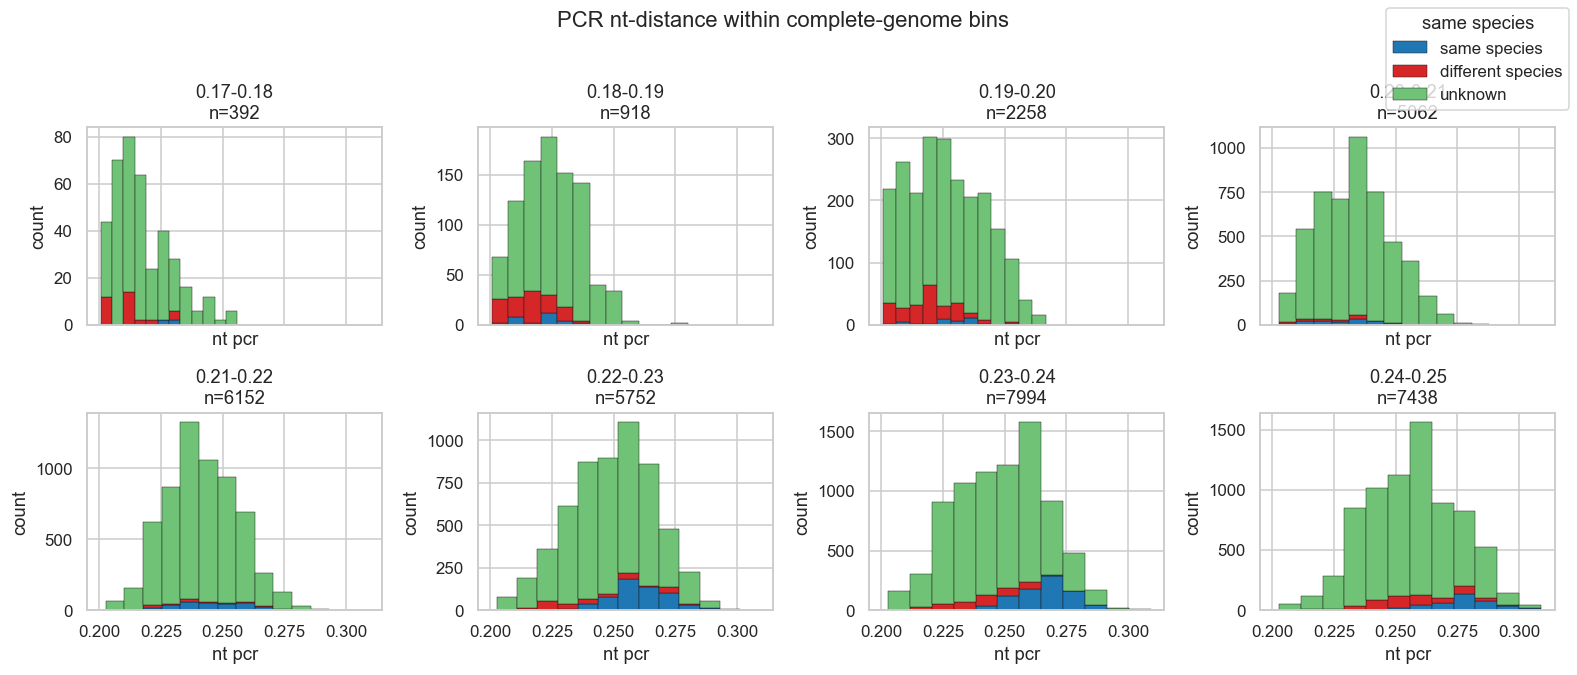

In [18]:
n_cols = 4
n_rows = int(np.ceil(len(bins_present) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6*n_cols, 3.0*n_rows),
                         sharex=True, sharey=False, squeeze=False)
axes = axes.ravel()

pal = {"yes": "#1f77b4", "no": "#d62728", "unknown": "#6fc276"}

for ax, lbl in zip(axes, bins_present):
    sub = df_plot[df_plot["bin_complete"] == lbl]
    arrays = [sub.loc[sub["same_species"] == s, "nt_pcr"].values for s in ["yes","no","unknown"]]
    ax.hist(arrays, bins=12, stacked=True,
            color=[pal["yes"], pal["no"], pal["unknown"]],
            edgecolor="k", linewidth=0.3,
            label=["yes","no","unknown"])
    ax.set_title(f"{lbl}\nn={len(sub)}")
    ax.set_xlabel("nt pcr"); ax.set_ylabel("count")

for ax in axes[len(bins_present):]:
    ax.axis("off")

handles = [plt.Rectangle((0,0),1,1, color=pal[s], ec="k", lw=0.3) for s in ["yes","no","unknown"]]
fig.legend(handles, ["same species","different species","unknown"],
           loc="upper right", title="same species")
fig.suptitle("PCR nt-distance within complete-genome bins", y=1.02)
plt.tight_layout()
plt.show()